In [ ]:
!python imageconverter.py

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, top_k_accuracy_score
from transformers import color_histogram
from pathlib import Path
import matplotlib.pyplot as plt


In [2]:
train_df = pd.read_csv("train_set.csv")
test_df = pd.read_csv("test_set.csv")

In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Columns: 147 entries, country_code to edge_density_bottom
dtypes: bool(1), float64(134), int64(5), str(7)
memory usage: 118.6 MB


In [4]:
print(train_df.index.is_unique, train_df.index.max(), len(train_df))
print(test_df.index.is_unique, test_df.index.max(), len(test_df))

True 96078 96079
True 10675 10676


In [5]:
missing_cc = train_df[train_df['country_code'].isna()]
print(missing_cc.groupby('country').size().sort_values(ascending=False))

country
Namibia         877
Botswana         14
South Africa      6
dtype: int64


Missing values are because of Namibia " NA ". Thats fine well drop all but country they all the same. 

In [6]:

feature_cols = [c for c in train_df.columns if c not in ["country", "image_name"]]



missing = train_df[feature_cols].isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False)
print(missing_df.to_string())

                    Missing Count  Missing %
country_code                  897       0.93
coord_country_code            888       0.92


In [7]:
train_df.keys()

Index(['country_code', 'image_name', 'width', 'height', 'size', 'path',
       'latitude', 'longitude', 'heading', 'country',
       ...
       'lbp_39', 'ground_hue_mean', 'ground_sat_mean', 'ground_val_mean',
       'ground_grey_frac', 'brightness_mean', 'contrast_std',
       'edge_density_total', 'edge_density_top', 'edge_density_bottom'],
      dtype='str', length=147)

In [8]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
lbp_0               lbp_9                  0.958615
lbp_10              lbp_19                 0.955514
lbp_1               lbp_9                  0.955226
vari_mean           vari_std               0.953062
lbp_11              lbp_19                 0.951424
lbp_30              lbp_39                 0.932188
lbp_20              lbp_29                 0.932166
lbp_0               lbp_1                  0.922506
lbp_10              lbp_11                 0.920591
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
lbp_31              lbp_39                 0.873769
lbp_21              lbp_29                 0.870919
hsv_bin_28          hsv_bin_29             0.865025
lbp_20              lbp_21                 0.844294
lbp_30              lbp_31                 0.840320
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34  

In [9]:
DATA_PATH = Path("data/images/streetview_images")

if not any(DATA_PATH.iterdir()):
    path = kagglehub.dataset_download(
        "sylshaw/streetview-by-country",
        output_dir=str(DATA_PATH)
    )
else:
    path = str(DATA_PATH)

print("Path to dataset:", path)

Path to dataset: data/images/streetview_images


In [10]:
old_hsv_cols = [c for c in train_df.columns if c.startswith('hsv_bin_')]
train_df = train_df.drop(columns=old_hsv_cols)
test_df = test_df.drop(columns=old_hsv_cols)

train_features = [color_histogram(path) for path in train_df['path']]
test_features = [color_histogram(path) for path in test_df['path']]

train_hsv_cols = pd.DataFrame(train_features, columns=[f'hsv_bin_{i}' for i in range(48)])
test_hsv_cols = pd.DataFrame(test_features, columns=[f'hsv_bin_{i}' for i in range(48)])

train_df = pd.concat([train_df.reset_index(drop=True), train_hsv_cols], axis=1)
test_df = pd.concat([test_df.reset_index(drop=True), test_hsv_cols], axis=1)

In [11]:
from sklearn.decomposition import PCA

def fit_full_pca(df):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA()
    pca.fit(df[lbp_cols])
    return pca

In [12]:

pca = fit_full_pca(train_df)

In [13]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)
print("Cumulative Variance:")
print(cumulative_variance)
print(f"Components for 80% variance: {np.argmax(cumulative_variance >= 0.80) + 1}")


Cumulative Variance:
[0.36931468 0.59649358 0.71509513 0.79284805 0.85406926 0.89512261
 0.93000495 0.94400384 0.95587638 0.96481216 0.96988139 0.97435668
 0.97786711 0.9802181  0.98246554 0.98445001 0.98576217 0.98702394
 0.9881589  0.9892409  0.99026265 0.9911956  0.99207872 0.99292138
 0.99368065 0.99440114 0.99511061 0.99577117 0.99642418 0.99704158
 0.99760882 0.99815381 0.99864783 0.99911758 0.99958382 1.
 1.         1.         1.         1.        ]
Components for 80% variance: 5


In [14]:

n_pca_components = 7

def apply_pca_to_lbp(df, n_components):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    pca = PCA(n_components=n_components)
    lbp_pca = pca.fit_transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df, pca

def transform_pca_lbp(df, pca):
    lbp_cols = [c for c in df.columns if c.startswith('lbp')]
    lbp_pca = pca.transform(df[lbp_cols])
    lbp_pca_cols = pd.DataFrame(lbp_pca, columns=[f'lbp_pca_{i}' for i in range(lbp_pca.shape[1])])
    df = pd.concat([df.drop(columns=lbp_cols).reset_index(drop=True), lbp_pca_cols], axis=1)
    return df


In [15]:
train_df, pca = apply_pca_to_lbp(train_df, n_pca_components)
test_df = transform_pca_lbp(test_df, pca)

In [16]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = corr_pairs[corr_pairs.abs() > 0.8].sort_values(ascending=False)

print(high_corr)

size                edge_density_total     0.966164
vari_mean           vari_std               0.953062
hsv_bin_29          hsv_bin_30             0.906666
size                edge_density_top       0.894092
edge_density_total  edge_density_top       0.891680
hsv_bin_28          hsv_bin_29             0.865025
hsv_bin_30          hsv_bin_31             0.836538
hsv_bin_34          hsv_bin_35             0.835752
hsv_bin_33          hsv_bin_34             0.827221
edge_density_total  edge_density_bottom    0.802613
dtype: float64


In [17]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns


In [18]:
feature_cols = [c for c in numeric_cols if c not in ["country", "image_name", "latitude", "longitude", "heading", "width", "height", "channels"]]

In [19]:
from sklearn.feature_selection import mutual_info_regression

mi_scores_lat = mutual_info_regression(train_df[feature_cols], train_df['latitude'], random_state=42)
mi_scores_lon = mutual_info_regression(train_df[feature_cols], train_df['longitude'], random_state=42)
mi_scores = (mi_scores_lat + mi_scores_lon) / 2

mi_importance = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)
print(mi_importance)

sky_fraction    0.213479
hsv_bin_31      0.180994
hsv_bin_47      0.178188
hsv_bin_26      0.173285
hsv_bin_27      0.173265
                  ...   
hog_pca_28      0.022886
hog_pca_16      0.022871
hog_pca_27      0.019392
lbp_pca_3       0.014312
lbp_pca_4       0.010946
Length: 100, dtype: float64


In [20]:
from sklearn.feature_selection import f_regression
f_scores_lat, _ = f_regression(train_df[feature_cols], train_df['latitude'])
f_scores_lon, _ = f_regression(train_df[feature_cols], train_df['longitude'])
f_scores = (f_scores_lat + f_scores_lon) / 2

feature_importance = pd.Series(f_scores, index=feature_cols).sort_values(ascending=False)
print(feature_importance)

hsv_bin_1          2957.139011
contrast_std       1479.323475
hsv_bin_3          1468.979844
ground_hue_mean    1064.005518
hsv_bin_28          987.267602
                      ...     
hog_pca_23            2.260679
hog_pca_18            1.409507
hsv_bin_40            0.752005
lbp_pca_4             0.412658
hog_pca_27            0.352149
Length: 100, dtype: float64


In [21]:
f_scores_series = pd.Series(f_scores, index=feature_cols)

In [22]:
drop_cols = ['country_code', 'width', 'height', 'size', 'path', 'coord_country_code',
             'corrupted', 'channels', 'phash', 'vari_std', 'hsv_bin_34', 'hsv_bin_29', 'edge_density_total', 'continent']

In [23]:
mi_threshold = mi_importance.quantile(0.2)
f_threshold = feature_importance.quantile(0.2)

drop_cols2 = [c for c in feature_cols if mi_importance[c] <= mi_threshold and f_scores_series[c] <= f_threshold]

In [24]:
train_df = train_df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)

In [25]:
train_df = train_df.drop(columns=drop_cols2)
test_df = test_df.drop(columns=drop_cols2)

In [26]:
feature_cols = [c for c in train_df.columns if c not in ["country", "image_name", "latitude", "longitude"]]

In [27]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Data columns (total 85 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   image_name           96079 non-null  str    
 1   latitude             96079 non-null  float64
 2   longitude            96079 non-null  float64
 3   heading              96079 non-null  int64  
 4   country              96079 non-null  str    
 5   vari_mean            96079 non-null  float64
 6   vari_frac            96079 non-null  float64
 7   sky_fraction         96079 non-null  float64
 8   sky_blue_ratio       96079 non-null  float64
 9   hog_pca_0            96079 non-null  float64
 10  hog_pca_1            96079 non-null  float64
 11  hog_pca_3            96079 non-null  float64
 12  hog_pca_5            96079 non-null  float64
 13  hog_pca_7            96079 non-null  float64
 14  hog_pca_8            96079 non-null  float64
 15  hog_pca_9            96079 non-null  float64
 1

In [28]:
skewness = train_df[feature_cols].skew().sort_values(ascending=False)

skewed_features = skewness[(skewness > 2) | (skewness < -2)]
skewed_df = pd.DataFrame({'feature': skewed_features.index, 'skewness': skewed_features.values})
print(skewed_df)

       feature   skewness
0   hsv_bin_32  34.094460
1   hsv_bin_14   7.066895
2    vari_mean   6.949759
3   hsv_bin_30   6.792065
4   hsv_bin_28   6.784120
5   hsv_bin_13   6.439854
6   hsv_bin_27   5.190380
7   hsv_bin_15   5.092590
8   hsv_bin_12   4.709504
9   hsv_bin_11   4.433482
10  hsv_bin_33   4.206103
11  hsv_bin_26   4.026585
12  hsv_bin_31   3.725032
13   hsv_bin_5   3.327745
14   hsv_bin_6   3.087945
15  hsv_bin_25   2.989727
16   hsv_bin_7   2.944304
17  hsv_bin_10   2.807677
18   hsv_bin_4   2.493907
19  hsv_bin_24   2.396733
20  hsv_bin_35   2.259421
21  hsv_bin_23   2.063125
22   hsv_bin_0   2.024697
23   lbp_pca_2  -2.436208


In [29]:
print((train_df[skewed_df['feature']] < 0).sum())

hsv_bin_32        0
hsv_bin_14        0
vari_mean     14008
hsv_bin_30        0
hsv_bin_28        0
hsv_bin_13        0
hsv_bin_27        0
hsv_bin_15        0
hsv_bin_12        0
hsv_bin_11        0
hsv_bin_33        0
hsv_bin_26        0
hsv_bin_31        0
hsv_bin_5         0
hsv_bin_6         0
hsv_bin_25        0
hsv_bin_7         0
hsv_bin_10        0
hsv_bin_4         0
hsv_bin_24        0
hsv_bin_35        0
hsv_bin_23        0
hsv_bin_0         0
lbp_pca_2     32667
dtype: int64


In [30]:
neg_cols = ['vari_mean', 'lbp_pca_2']
log_cols = [c for c in skewed_df['feature'] if c not in neg_cols]

for col in log_cols:
    train_df[col] = np.log1p(train_df[col])
    test_df[col] = np.log1p(test_df[col])

for col in ['vari_mean']:
    train_df[col] = np.sign(train_df[col]) * np.log1p(np.abs(train_df[col]))
    test_df[col] = np.sign(test_df[col]) * np.log1p(np.abs(test_df[col]))

In [31]:
def winsorize_continuous_train_test(df_train, df_test, lower_pct=0.01, upper_pct=0.99):
    df_train = df_train.copy()
    df_test = df_test.copy()
    continuous_cols = [c for c in df_train.columns if c not in ["country", "image_name", "latitude", "longitude"]]

    for col in continuous_cols:
        if col in df_train.columns:
            lo = df_train[col].quantile(lower_pct)
            hi = df_train[col].quantile(upper_pct)
            n_outliers_train = ((df_train[col] < lo) | (df_train[col] > hi)).sum()
            df_train[col] = df_train[col].clip(lo, hi)
            df_test[col] = df_test[col].clip(lo, hi)

    return df_train, df_test

In [32]:
train_df, test_df = winsorize_continuous_train_test(train_df, test_df)

In [33]:
from sklearn.preprocessing import StandardScaler


feature_cols = [c for c in train_df.columns if c not in ["country", "image_name", "latitude", "longitude"]]

scaler = StandardScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

In [34]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96079 entries, 0 to 96078
Data columns (total 85 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   image_name           96079 non-null  str    
 1   latitude             96079 non-null  float64
 2   longitude            96079 non-null  float64
 3   heading              96079 non-null  float64
 4   country              96079 non-null  str    
 5   vari_mean            96079 non-null  float64
 6   vari_frac            96079 non-null  float64
 7   sky_fraction         96079 non-null  float64
 8   sky_blue_ratio       96079 non-null  float64
 9   hog_pca_0            96079 non-null  float64
 10  hog_pca_1            96079 non-null  float64
 11  hog_pca_3            96079 non-null  float64
 12  hog_pca_5            96079 non-null  float64
 13  hog_pca_7            96079 non-null  float64
 14  hog_pca_8            96079 non-null  float64
 15  hog_pca_9            96079 non-null  float64
 1

In [35]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
train_idx, val_idx = next(splitter.split(train_df, train_df["country"]))

train_split = train_df.iloc[train_idx]
val_split = train_df.iloc[val_idx]

In [36]:
train_names = train_split["image_name"].copy()
val_names = val_split["image_name"].copy()
test_names = test_df["image_name"].copy()

y_train = train_split[["latitude", "longitude"]].copy()
y_val = val_split[["latitude", "longitude"]].copy()
y_test = test_df[["latitude", "longitude"]].copy()

X_train_raw = train_split.drop(columns=["image_name", "country", "latitude", "longitude"]).copy()
X_val_raw = val_split.drop(columns=["image_name", "country", "latitude", "longitude"]).copy()
X_test_raw = test_df.drop(columns=["image_name", "country", "latitude", "longitude"]).copy()

print(f"training features shape: {X_train_raw.shape}")
print(f"validation features shape: {X_val_raw.shape}")
print(f"test features shape: {X_test_raw.shape}")

training features shape: (86471, 81)
validation features shape: (9608, 81)
test features shape: (10676, 81)


In [37]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

def print_km_stats(y_true, preds, label):
    y_true = np.array(y_true)
    dist = haversine_distance(y_true[:,0], y_true[:,1], preds[:,0], preds[:,1])
    print(f"{label} mean km: {dist.mean():.1f}  median km: {np.median(dist):.1f}")

In [38]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train_raw, y_train)
val_pred = lr_model.predict(X_val_raw)
print_km_stats(y_val, val_pred, "LR")

LR mean km: 5507.2  median km: 4120.6


In [39]:
from sklearn.linear_model import Ridge

ridge_model = Ridge()
ridge_model.fit(X_train_raw, y_train)
val_pred = ridge_model.predict(X_val_raw)
print_km_stats(y_val, val_pred, "Ridge")

Ridge mean km: 5507.2  median km: 4120.5


In [40]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_raw, y_train)
val_pred = dt_model.predict(X_val_raw)
print_km_stats(y_val, val_pred, "Decision Tree")

Decision Tree mean km: 6165.6  median km: 5853.6


In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(X_train_raw, y_train)
val_pred = rf_model.predict(X_val_raw)
print_km_stats(y_val, val_pred, "Random Forest")

Random Forest mean km: 5119.3  median km: 3800.5


In [42]:
from sklearn.metrics import make_scorer

def haversine_score(y_true, y_pred):
    y_true = np.array(y_true)
    return haversine_distance(y_true[:,0], y_true[:,1], y_pred[:,0], y_pred[:,1]).mean()

haversine_scorer = make_scorer(haversine_score, greater_is_better=False)

In [43]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV


In [44]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 25],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), rf_param_grid, n_iter=15, cv=3, scoring=haversine_scorer, random_state=42)
rf_search.fit(X_train_raw, y_train)

print(rf_search.best_params_)
print(rf_search.best_score_)

{'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 25}
-5178.402816174971


In [45]:
from sklearn.model_selection import GridSearchCV

ridge_param_grid = {"alpha": [0.1, 1, 10, 100]}

ridge_search = GridSearchCV(Ridge(), ridge_param_grid, cv=3, scoring=haversine_scorer, n_jobs=-1)
ridge_search.fit(X_train_raw, y_train)

print(ridge_search.best_params_)
print(ridge_search.best_score_)

{'alpha': 0.1}
-5523.7328730590925


In [46]:
best_rf = rf_search.best_estimator_
test_pred_rf = best_rf.predict(X_test_raw)
print_km_stats(y_test, test_pred_rf, "RF Test")

RF Test mean km: 5132.0  median km: 3773.4


In [47]:
best_ridge = ridge_search.best_estimator_
test_pred_ridge = best_ridge.predict(X_test_raw)
print_km_stats(y_test, test_pred_ridge, "Ridge Test")

Ridge Test mean km: 5528.3  median km: 4126.1


In [48]:
ensemble_pred = (test_pred_rf + test_pred_ridge) / 2
print_km_stats(y_test, ensemble_pred, "Ensemble Average")

Ensemble Average mean km: 5303.4  median km: 3895.2


In [49]:
meta_X_val = np.hstack([best_rf.predict(X_val_raw), best_ridge.predict(X_val_raw)])
meta_X_test = np.hstack([test_pred_rf, test_pred_ridge])

meta_model = LinearRegression()
meta_model.fit(meta_X_val, y_val)

stack_pred = meta_model.predict(meta_X_test)
print_km_stats(y_test, stack_pred, "Stacked")

Stacked mean km: 4827.7  median km: 3612.6


In [50]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_raw.columns).sort_values(ascending=False)
print(importances.to_string())

lbp_pca_2              0.022121
ground_hue_mean        0.020700
hsv_bin_32             0.017769
hsv_bin_1              0.016697
lbp_pca_5              0.015871
ground_grey_frac       0.014971
edge_density_bottom    0.014939
hsv_bin_47             0.014823
hog_pca_3              0.014748
ground_sat_mean        0.014247
vari_mean              0.013926
hog_pca_0              0.013773
lbp_pca_1              0.013763
edge_density_top       0.013753
hsv_bin_3              0.013724
hog_pca_7              0.013488
hsv_bin_10             0.013354
hsv_bin_31             0.013313
hsv_bin_24             0.013313
hsv_bin_13             0.013062
hsv_bin_25             0.013044
vari_frac              0.013043
sky_fraction           0.012982
hsv_bin_23             0.012942
hsv_bin_2              0.012940
hog_pca_8              0.012750
lbp_pca_0              0.012640
hsv_bin_9              0.012627
ground_val_mean        0.012609
hsv_bin_15             0.012604
hsv_bin_26             0.012577
hsv_bin_

In [51]:
import reverse_geocoder as rg

def snap_to_land(preds):
    results = rg.search(list(zip(preds[:,0], preds[:,1])), mode=1)
    return np.array([[float(r['lat']), float(r['lon'])] for r in results])

test_pred_land = snap_to_land(test_pred_rf)

print_km_stats(y_test, test_pred_rf, "Hedge (unconstrained)")
print_km_stats(y_test, test_pred_land, "Land-only (snapped)")

Loading formatted geocoded file...
Hedge (unconstrained) mean km: 5132.0  median km: 3773.4
Land-only (snapped) mean km: 5131.3  median km: 3777.2


/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/pedrosalgado22/.local/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/pedrosalgado22/.local/lib/python3.14/site-packages/s

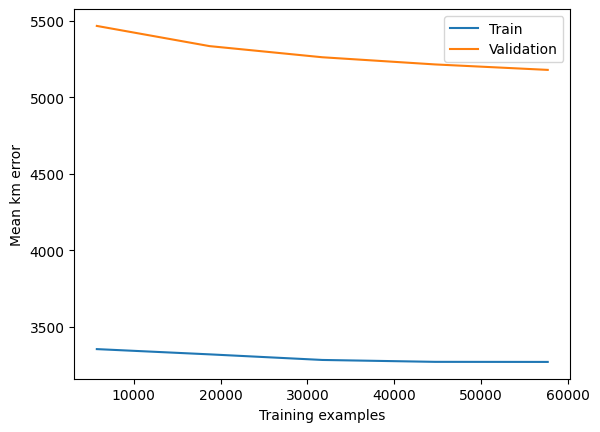

In [52]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_rf, X_train_raw, y_train, cv=3, scoring=haversine_scorer, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=42
)

plt.plot(train_sizes, -train_scores.mean(axis=1), label='Train')
plt.plot(train_sizes, -val_scores.mean(axis=1), label='Validation')
plt.xlabel("Training examples")
plt.ylabel("Mean km error")
plt.legend()
plt.show()